In [2]:
import tables

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table
    print("=== ATTRIBUTES ===")

    for attr in table.attrs._v_attrnames:
        try:
            value = getattr(table.attrs, attr)
            print(f"\n{attr}:")
            print(value)
        except Exception as e:
            print(f"\n{attr}: ERROR -> {e}")

=== ATTRIBUTES ===

CLASS:
TABLE

FIELD_0_FILL:
0

FIELD_0_NAME:
index

FIELD_1_FILL:
0.0

FIELD_1_NAME:
values_block_0

FIELD_2_FILL:
0

FIELD_2_NAME:
values_block_1

NROWS:
1211000

TITLE:


VERSION:
2.7

index_kind:
b'integer'

values_block_0_dtype:
b'float32'

values_block_0_kind:
['E_0', 'PX_0', 'PY_0', 'PZ_0', 'E_1', 'PX_1', 'PY_1', 'PZ_1', 'E_2', 'PX_2', 'PY_2', 'PZ_2', 'E_3', 'PX_3', 'PY_3', 'PZ_3', 'E_4', 'PX_4', 'PY_4', 'PZ_4', 'E_5', 'PX_5', 'PY_5', 'PZ_5', 'E_6', 'PX_6', 'PY_6', 'PZ_6', 'E_7', 'PX_7', 'PY_7', 'PZ_7', 'E_8', 'PX_8', 'PY_8', 'PZ_8', 'E_9', 'PX_9', 'PY_9', 'PZ_9', 'E_10', 'PX_10', 'PY_10', 'PZ_10', 'E_11', 'PX_11', 'PY_11', 'PZ_11', 'E_12', 'PX_12', 'PY_12', 'PZ_12', 'E_13', 'PX_13', 'PY_13', 'PZ_13', 'E_14', 'PX_14', 'PY_14', 'PZ_14', 'E_15', 'PX_15', 'PY_15', 'PZ_15', 'E_16', 'PX_16', 'PY_16', 'PZ_16', 'E_17', 'PX_17', 'PY_17', 'PZ_17', 'E_18', 'PX_18', 'PY_18', 'PZ_18', 'E_19', 'PX_19', 'PY_19', 'PZ_19', 'E_20', 'PX_20', 'PY_20', 'PZ_20', 'E_21', 'PX_21', '

In [3]:
!pip install grap


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [4]:
import tables
import pandas as pd

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table

    attrs = {}

    for attr in table.attrs._v_attrnames:
        try:
            value = getattr(table.attrs, attr)
            attrs[attr] = str(value)
        except Exception as e:
            attrs[attr] = f"ERROR: {e}"

df_attrs = pd.DataFrame(
    list(attrs.items()),
    columns=["Attribute", "Value"]
)

print(df_attrs)

               Attribute                                              Value
0                  CLASS                                              TABLE
1           FIELD_0_FILL                                                  0
2           FIELD_0_NAME                                              index
3           FIELD_1_FILL                                                0.0
4           FIELD_1_NAME                                     values_block_0
5           FIELD_2_FILL                                                  0
6           FIELD_2_NAME                                     values_block_1
7                  NROWS                                            1211000
8                  TITLE                                                   
9                VERSION                                                2.7
10            index_kind                                         b'integer'
11  values_block_0_dtype                                         b'float32'
12   values_

In [5]:
import tables

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table

    data = table.read(start=0, stop=5)

    print(data["values_block_1"])

[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]]


In [6]:
import tables
import pandas as pd

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table
    data = table.read()

df = pd.DataFrame({
    "ttv": data["values_block_1"][:, 0],
    "is_signal_new": data["values_block_1"][:, 1]
})

print(df.head())
print(df["is_signal_new"].value_counts())

   ttv  is_signal_new
0    0              0
1    0              0
2    0              0
3    0              0
4    0              0
is_signal_new
0    605523
1    605477
Name: count, dtype: int64


In [7]:
import tables
import pandas as pd

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table

    # Read constituent features
    data = table.read()

    # Extract the 800 constituent features
    constituents = data["values_block_0"]

    # Get feature names from the table attributes
    feature_names = table.attrs.values_block_0_kind

    # Convert names to a regular Python list if necessary
    feature_names = list(feature_names)

    # Create Pandas DataFrame
    df_constituents = pd.DataFrame(
        constituents,
        columns=feature_names
    )

print("Shape:", df_constituents.shape)
print(df_constituents.head())

Shape: (1211000, 804)
          E_0        PX_0        PY_0        PZ_0         E_1        PX_1  \
0  474.071136 -250.347031 -223.651962 -334.738098  103.236237  -48.866222   
1  150.504532  120.062393   76.852005  -48.274265   82.257057   63.801739   
2  251.645386   10.427651 -147.573746  203.564880  104.147797   10.718256   
3  451.566132  129.885437  -99.066292 -420.984100  208.410919   59.033958   
4  399.093903 -168.432083  -47.205597 -358.717438  273.691956 -121.926941   

        PY_1        PZ_1         E_2       PX_2  ...  PY_198  PZ_198  E_199  \
0 -56.790775  -71.025490  105.255569 -55.415001  ...     0.0     0.0    0.0   
1  42.754807  -29.454842   48.573559  36.763199  ...     0.0     0.0    0.0   
2 -54.497948   88.101395   78.043213   5.724113  ...     0.0     0.0    0.0   
3 -46.177090 -194.467941  190.183304  54.069675  ...     0.0     0.0    0.0   
4 -30.803854 -243.088928  152.837219 -44.400204  ...     0.0     0.0    0.0   

   PX_199  PY_199  PZ_199  truthE  truth

In [4]:
import tables
import pandas as pd

N = 100_000

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table

    feature_names = list(table.attrs.values_block_0_kind)

    X_train = pd.DataFrame(
        table.read(
            field="values_block_0",
            start=0,
            stop=N
        )[:, :800],
        columns=feature_names[:800]
    )

    y_train = pd.Series(
        table.read(
            field="values_block_1",
            start=0,
            stop=N
        )[:, 1],
        name="is_signal_new"
    )

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print(y_train.value_counts())
display(X_train.head(20))
# display(y_train.head(50))

X_train: (100000, 800)
y_train: (100000,)
is_signal_new
1    50040
0    49960
Name: count, dtype: int64


,E_0,PX_0,PY_0,PZ_0,E_1,PX_1,PY_1,PZ_1,E_2,PX_2,...,PY_197,PZ_197,E_198,PX_198,PY_198,PZ_198,E_199,PX_199,PY_199,PZ_199
0,474.071136,-250.347031,-223.651962,-334.738098,103.236237,-48.866222,-56.790775,-71.025490,105.255569,-55.415001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,150.504532,120.062393,76.852005,-48.274265,82.257057,63.801739,42.754807,-29.454842,48.573559,36.763199,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,251.645386,10.427651,-147.573746,203.564880,104.147797,10.718256,-54.497948,88.101395,78.043213,5.724113,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,451.566132,129.885437,-99.066292,-420.984100,208.410919,59.033958,-46.177090,-194.467941,190.183304,54.069675,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,399.093903,-168.432083,-47.205597,-358.717438,273.691956,-121.926941,-30.803854,-243.088928,152.837219,-44.400204,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,306.275299,96.237411,-27.163664,289.491028,283.876953,90.638680,-31.638950,267.151154,262.165558,83.561035,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,146.247421,66.247086,-42.599674,-123.227028,189.950287,58.527752,-45.889629,-174.784882,151.716171,45.033234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,169.186386,-29.472824,86.933357,142.119583,83.599068,-11.078982,42.814793,70.943314,46.992054,-7.090906,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,142.818451,-80.388260,115.831711,22.756336,96.153008,-54.599506,77.578491,15.680322,88.052628,-49.205051,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,367.854797,142.678009,-15.802814,-338.689270,296.485931,114.453636,-11.433640,-273.264618,120.646027,49.435143,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
import pandas as pd # to load and manipulate data and for One-Hot Encoding
import numpy as np # to calculate the mean and standard deviation
import matplotlib.pyplot as plt # to draw graphs
from sklearn.tree import DecisionTreeClassifier # to build a classification tree
from sklearn.tree import plot_tree # to draw a classification tree
from sklearn.model_selection import train_test_split # to split data into training and testing sets
from sklearn.model_selection import cross_val_score # for cross validation
from sklearn.metrics import ConfusionMatrixDisplay # creates and draws a confusion matrix
import xgboost as xgb #for bosted classifier xgboost is somehow better option for the jet particle physics
# from sklearn.metrics import plot_confusion_matrix # to draw a confusion matrix

In [7]:
## create a decisiont tree and fit it to the training data


clf_bdt = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic", # Uses LogLoss automatically
    random_state=42,
    n_jobs=-1                    # Uses all your CPU cores for speed
)

clf_bdt.fit(X_train, y_train)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


/home/uzair-sadozai/Desktop/hep-ml-cloud/.venv/lib/python3.14/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


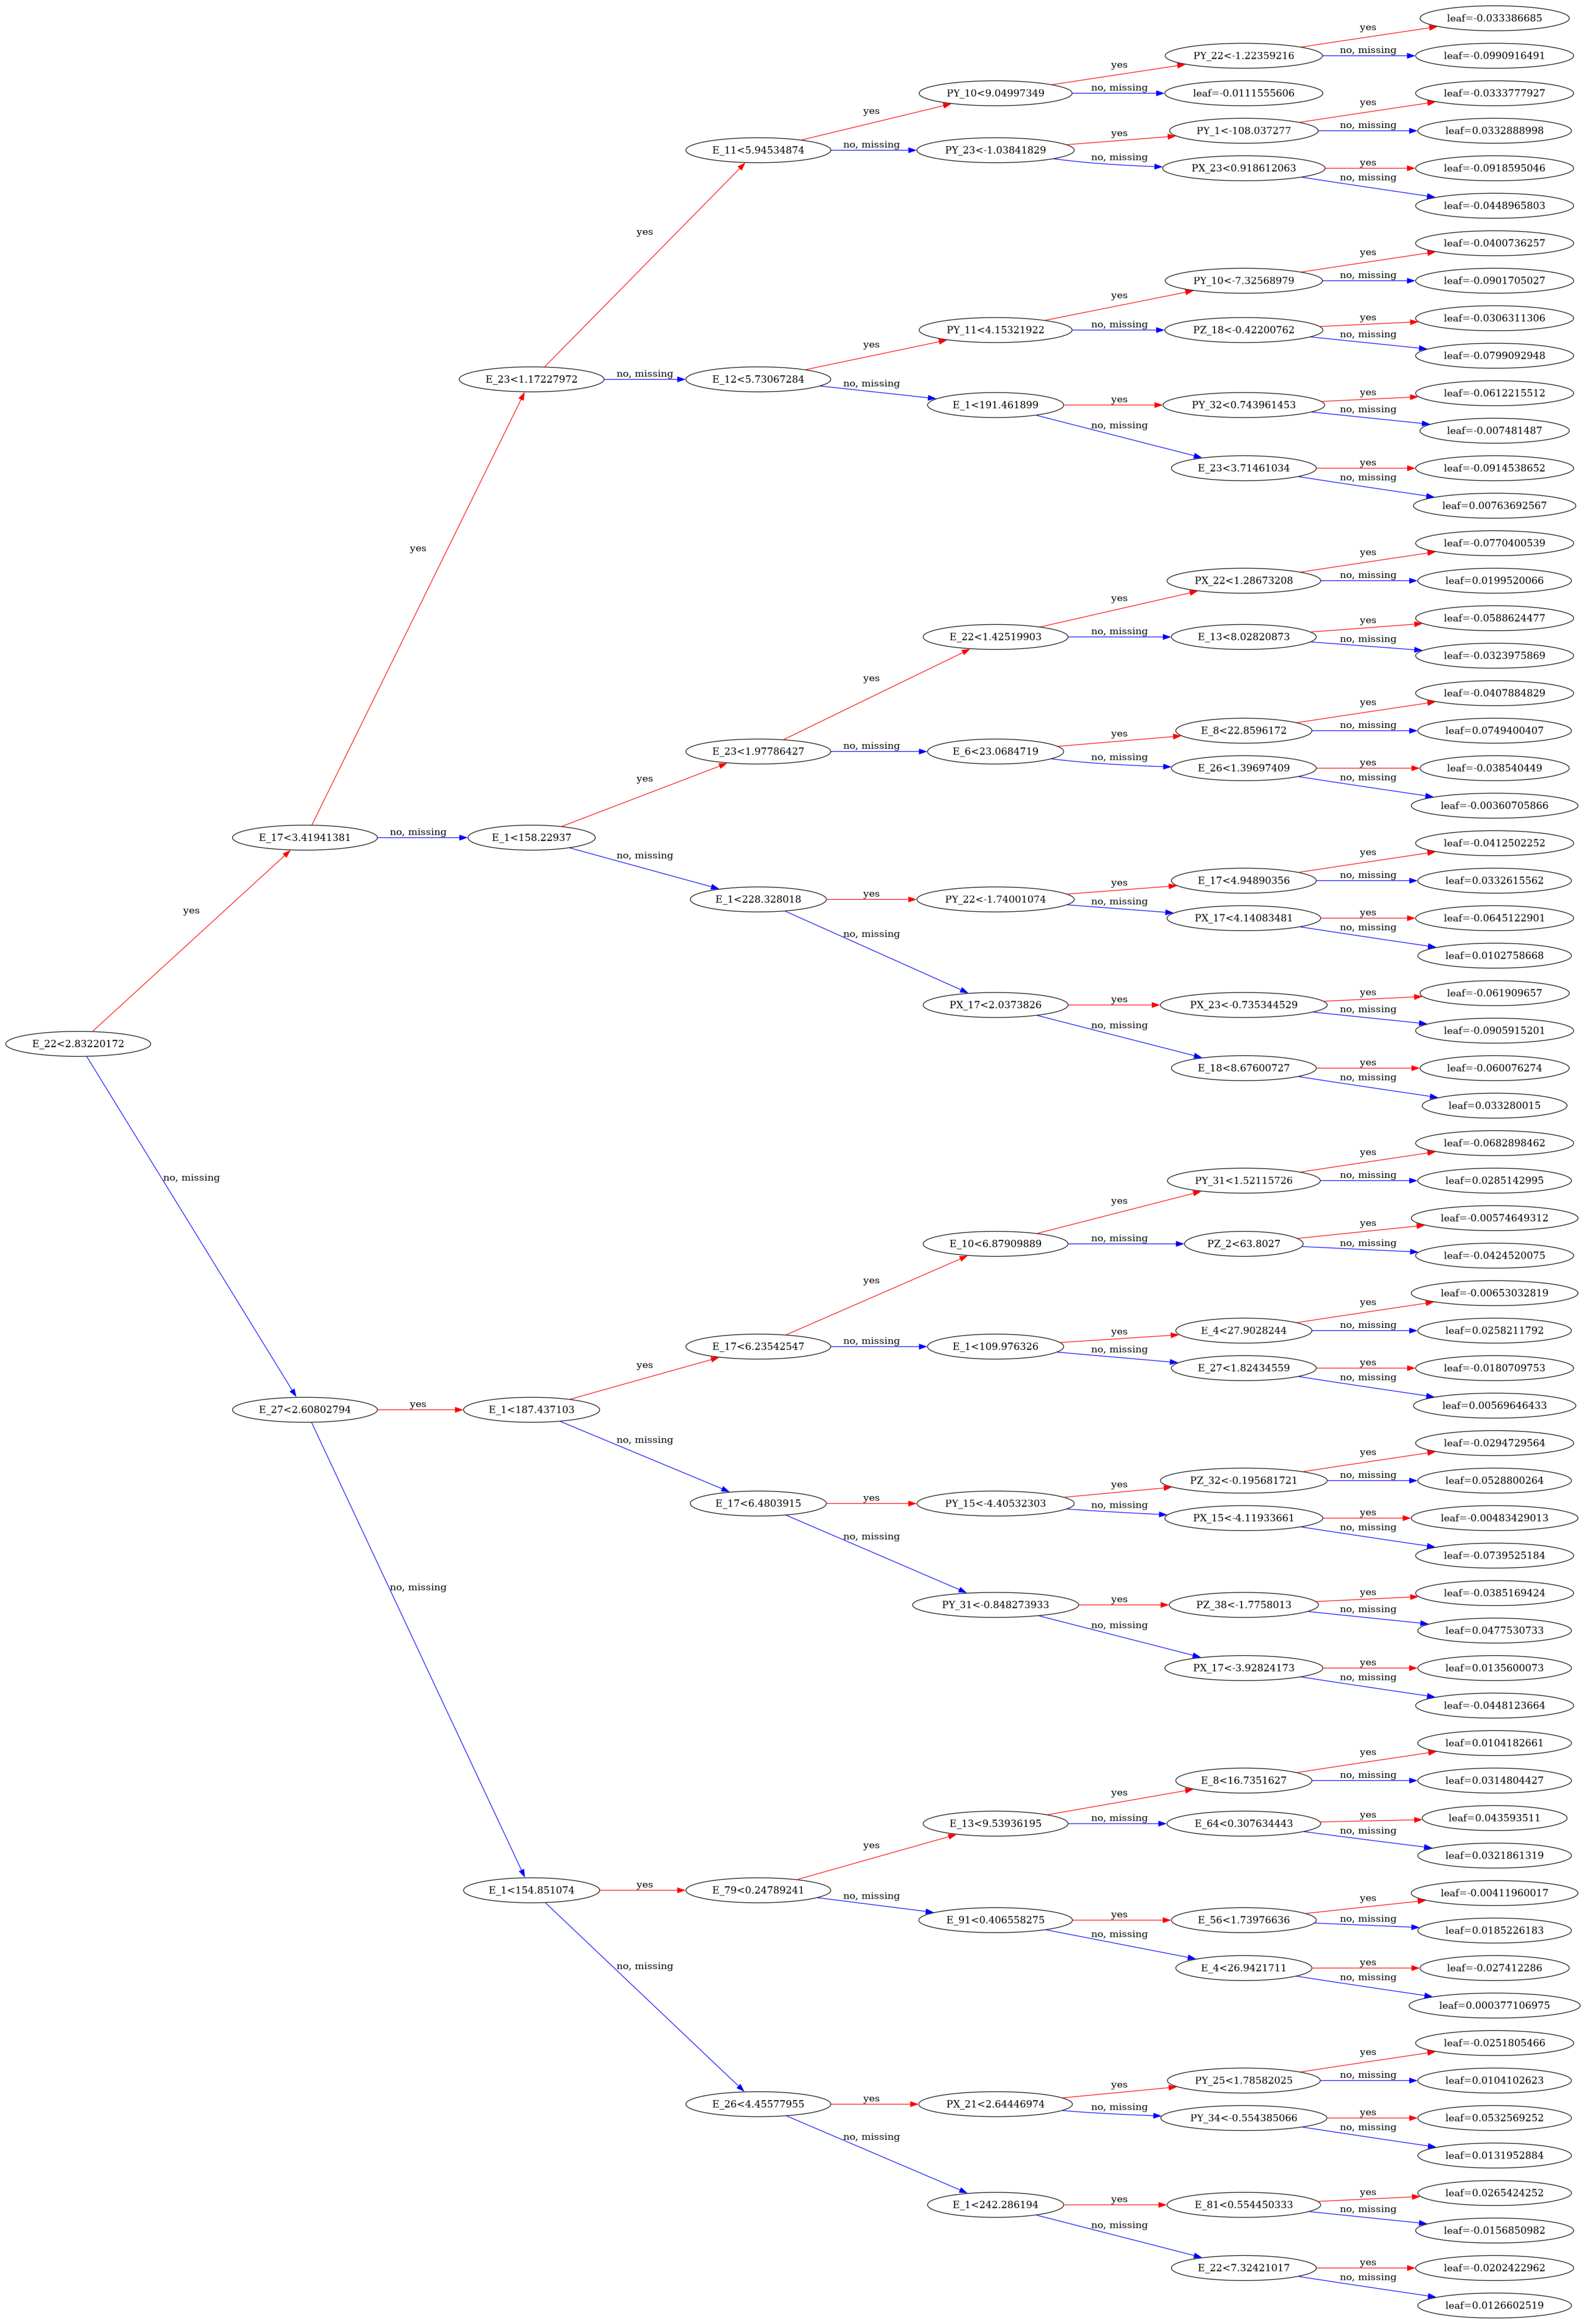

In [8]:
import matplotlib.pyplot as plt
import xgboost as xgb

xgb.plot_tree(clf_bdt, num_trees=0, rankdir="LR")
plt.gcf().set_size_inches(200, 100)
plt.show()

In [9]:
import tables
import pandas as pd

N = 100_000

with tables.open_file("val.h5", mode="r") as h5:
    table = h5.root.table.table

    feature_names = list(table.attrs.values_block_0_kind)

    X_val = pd.DataFrame(
        table.read(
            field="values_block_0",
            start=0,
            stop=N
        )[:, :800],
        columns=feature_names[:800]
    )

    y_val = pd.Series(
        table.read(
            field="values_block_1",
            start=0,
            stop=N
        )[:, 1],
        name="is_signal_new"
    )

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print(y_val.value_counts())
display(X_val.head(20))
# display(y_train.head(50))

X_val: (100000, 800)
y_val: (100000,)
is_signal_new
1    50190
0    49810
Name: count, dtype: int64


,E_0,PX_0,PY_0,PZ_0,E_1,PX_1,PY_1,PZ_1,E_2,PX_2,...,PY_197,PZ_197,E_198,PX_198,PY_198,PZ_198,E_199,PX_199,PY_199,PZ_199
0,266.676880,85.227501,-227.714478,109.539703,145.654129,46.856384,-124.277214,59.789429,76.116646,24.653267,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,385.807739,82.459038,303.009888,-224.127502,107.484184,15.370172,85.792786,-62.898380,69.148743,14.434706,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,144.535309,-108.092529,93.247643,-22.612755,70.963295,-21.669872,46.335262,-49.185867,56.287312,-19.737480,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,82.668480,49.805248,-9.679499,-65.267319,58.262596,38.636459,-7.670141,-42.929283,59.068157,37.110703,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,406.581726,186.811081,-345.960571,103.545181,42.170246,19.375856,-35.882679,10.739602,36.417843,12.717323,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,383.579987,-2.425069,331.046387,-193.742126,59.478207,-21.276777,52.788219,-17.273096,48.719555,-4.679730,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,145.315002,1.308301,130.312241,64.291985,106.912674,1.862807,97.060287,44.790062,34.371437,0.424950,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,257.993561,-56.336994,206.284210,144.338623,229.137405,-65.462891,180.365311,125.247421,127.783592,-27.591572,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,481.208313,-129.306366,105.096413,-451.437744,454.156525,-120.728462,100.163246,-426.204315,125.675858,-34.692989,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,87.898865,-4.744920,85.308998,-20.641462,55.467308,6.759329,53.698742,-12.139971,38.524090,-19.097017,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


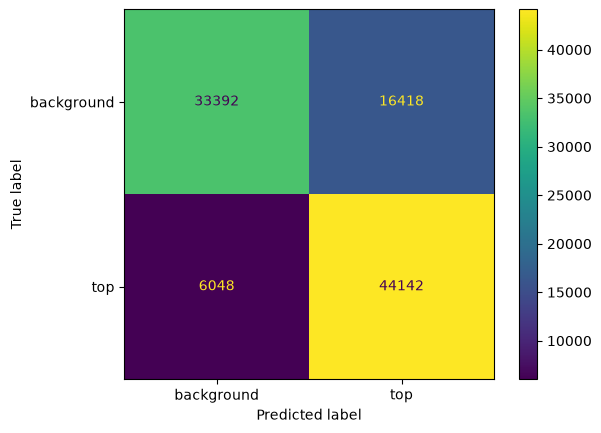

In [10]:
## plot_confusion_matrix() will run the test data down the tree and draw
## a confusion matrix.
ConfusionMatrixDisplay.from_estimator(clf_bdt, 
                                      X_val, 
                                      y_val, 
                                      display_labels=["background", "top"])

In [11]:
# Function for computing accuracy, precision, recall, and F1 score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred):
    """Helper function to compute accuracy, precision, recall, and F1 score at once."""
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Pretty print the metrics
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

In [12]:
# Testing model on training sets
y_train_pred = clf_bdt.predict(X_train)

# Compute metrics for training sets
print("Training Set Metrics:")
compute_metrics(y_train, y_train_pred)


Training Set Metrics:
Accuracy: 0.8410
Precision: 0.7906
Recall: 0.9280
F1 Score: 0.8538


In [13]:
# Testing model on test sets
y_val_pred = clf_bdt.predict(X_val)

# Compute metrics for test sets
print("validation Set Metrics:")
compute_metrics(y_val, y_val_pred)

validation Set Metrics:
Accuracy: 0.7753
Precision: 0.7289
Recall: 0.8795
F1 Score: 0.7971


In [14]:
import numpy as np
import pandas as pd
import tables

def calculate_physics_features(h5_path, N=50_000, chunk_size=5_000):
    all_features = []
    all_labels = []

    with tables.open_file(h5_path, mode="r") as h5:
        table = h5.root.table.table
        n_rows = min(N, table.nrows)

        for start in range(0, n_rows, chunk_size):
            stop = min(start + chunk_size, n_rows)

            # Read constituent four-momenta only: 200 x (E, PX, PY, PZ)
            block = table.read(
                field="values_block_0",
                start=start,
                stop=stop
            )[:, :800]

            jets = block.reshape(-1, 200, 4).astype(np.float64)

            E  = jets[:, :, 0]
            px = jets[:, :, 1]
            py = jets[:, :, 2]
            pz = jets[:, :, 3]

            # Constituent-level observables
            pt = np.sqrt(px**2 + py**2)
            phi = np.arctan2(py, px)

            eta = np.zeros_like(pt)
            valid = pt > 1e-12
            eta[valid] = np.arcsinh(
                pz[valid] / pt[valid]
            )

            # Ignore zero-padded constituents
            active = (E != 0) | (pt != 0) | (pz != 0)
            pt_active = np.where(active, pt, 0.0)
            sum_pt = pt_active.sum(axis=1)

            # Total jet four-momentum
            E_jet = E.sum(axis=1)
            px_jet = px.sum(axis=1)
            py_jet = py.sum(axis=1)
            pz_jet = pz.sum(axis=1)

            pt_jet = np.sqrt(px_jet**2 + py_jet**2)
            p2_jet = px_jet**2 + py_jet**2 + pz_jet**2

            # Small negative values from numerical precision -> 0
            mass2 = E_jet**2 - p2_jet
            mass_jet = np.sqrt(np.maximum(mass2, 0.0))

            eta_jet = np.zeros_like(pt_jet)
            valid_jet = pt_jet > 1e-12
            eta_jet[valid_jet] = np.arcsinh(
                pz_jet[valid_jet] / pt_jet[valid_jet]
            )

            phi_jet = np.arctan2(py_jet, px_jet)
            multiplicity = active.sum(axis=1)

            # Angular distance from each constituent to the jet axis
            dphi = np.arctan2(
                np.sin(phi - phi_jet[:, None]),
                np.cos(phi - phi_jet[:, None])
            )
            deta = eta - eta_jet[:, None]
            delta_R = np.sqrt(deta**2 + dphi**2)

            # pT-weighted radial moment (jet girth)
            girth = np.divide(
                (pt_active * delta_R).sum(axis=1),
                sum_pt,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            # pT dispersion
            pt_dispersion = np.sqrt(
                np.divide(
                    (pt_active**2).sum(axis=1),
                    sum_pt**2,
                    out=np.zeros_like(sum_pt),
                    where=sum_pt > 0
                )
            )

            # Approximate N-subjettiness, beta=1, R0=0.8.
            # tau1: jet axis; tau2: two leading-pT constituent axes.
            # This is a simple proxy, NOT a standard optimized tau21.
            R0 = 0.8
            tau1 = np.divide(
                (pt_active * delta_R).sum(axis=1),
                sum_pt * R0,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            order = np.argsort(-pt_active, axis=1)
            rows = np.arange(len(jets))
            idx1 = order[:, 0]
            idx2 = order[:, 1]

            eta1, phi1 = eta[rows, idx1], phi[rows, idx1]
            eta2, phi2 = eta[rows, idx2], phi[rows, idx2]

            dr1 = np.sqrt(
                (eta - eta1[:, None])**2
                + np.arctan2(
                    np.sin(phi - phi1[:, None]),
                    np.cos(phi - phi1[:, None])
                )**2
            )
            dr2 = np.sqrt(
                (eta - eta2[:, None])**2
                + np.arctan2(
                    np.sin(phi - phi2[:, None]),
                    np.cos(phi - phi2[:, None])
                )**2
            )

            tau2 = np.divide(
                (pt_active * np.minimum(dr1, dr2)).sum(axis=1),
                sum_pt * R0,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            tau21 = np.divide(
                tau2, tau1,
                out=np.zeros_like(tau2),
                where=tau1 > 1e-12
            )

            features = pd.DataFrame({
                "jet_mass": mass_jet,
                "jet_pt": pt_jet,
                "jet_eta": eta_jet,
                "jet_phi": phi_jet,
                "constituent_multiplicity": multiplicity,
                "jet_girth": girth,
                "pt_dispersion": pt_dispersion,
                "tau1_approx": tau1,
                "tau2_approx": tau2,
                "tau21_approx": tau21
            })

            # Read classification labels: 1 = top, 0 = QCD
            label_block = table.read(
                field="values_block_1",
                start=start,
                stop=stop
            )
            labels = label_block[:, 1]

            all_features.append(features)
            all_labels.append(labels)

    X = pd.concat(all_features, ignore_index=True)
    y = pd.Series(
        np.concatenate(all_labels),
        name="is_signal_new"
    )

    return X, y

In [15]:
X_train, y_train = calculate_physics_features(
    "train.h5",
    N=100_000
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print(y_train.value_counts())

display(X_train.head())
display(y_train.head())

X_train shape: (100000, 10)
y_train shape: (100000,)
is_signal_new
1    50040
0    49960
Name: count, dtype: int64


,jet_mass,jet_pt,jet_eta,jet_phi,constituent_multiplicity,jet_girth,pt_dispersion,tau1_approx,tau2_approx,tau21_approx
0,37.395616,617.077017,-0.874543,-2.400258,23,0.034444,0.573756,0.043055,0.013138,0.305135
1,46.999459,556.271305,-0.360226,0.578900,43,0.043689,0.331117,0.054611,0.039329,0.720165
2,61.650285,551.548764,1.185970,-1.471082,41,0.087534,0.324526,0.109417,0.080511,0.735814
3,52.105987,613.708732,-1.682899,-0.657215,25,0.025172,0.362092,0.031465,0.025379,0.806588
4,174.351456,622.304480,-1.526301,-2.894216,73,0.210092,0.357448,0.262615,0.200857,0.764834


0    0
1    0
2    0
3    0
4    0
Name: is_signal_new, dtype: int64

In [16]:
X_val, y_val = calculate_physics_features(
    "val.h5",
    N=100_000
)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print(y_val.value_counts())

display(X_val.head())
display(y_val.head())

X_val shape: (100000, 10)
y_val shape: (100000,)
is_signal_new
1    50190
0    49810
Name: count, dtype: int64


,jet_mass,jet_pt,jet_eta,jet_phi,constituent_multiplicity,jet_girth,pt_dispersion,tau1_approx,tau2_approx,tau21_approx
0,29.406393,566.683091,0.428453,-1.209822,20,0.021972,0.508605,0.027465,0.020589,0.749641
1,157.048399,629.077348,-0.624132,1.248070,41,0.158071,0.525701,0.197589,0.124658,0.630897
2,226.969283,571.624339,-0.618911,2.227796,43,0.361443,0.308696,0.451804,0.102311,0.226450
3,96.668965,567.747486,-0.941343,-0.236163,71,0.138121,0.193946,0.172651,0.140790,0.815459
4,45.342141,601.138636,0.272787,-1.111730,19,0.057923,0.662458,0.072404,0.050451,0.696796


0    0
1    0
2    0
3    0
4    0
Name: is_signal_new, dtype: int64

In [17]:
print("Training classes:")
print(y_train.value_counts(normalize=True))

print("\nValidation classes:")
print(y_val.value_counts(normalize=True))

print("\nMissing values in training:", X_train.isna().sum().sum())
print("Missing values in validation:", X_val.isna().sum().sum())

Training classes:
is_signal_new
1    0.5004
0    0.4996
Name: proportion, dtype: float64

Validation classes:
is_signal_new
1    0.5019
0    0.4981
Name: proportion, dtype: float64

Missing values in training: 0
Missing values in validation: 0


In [18]:
clf_bdt = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic", # Uses LogLoss automatically
    random_state=42,
    n_jobs=-1                    # Uses all your CPU cores for speed
)

clf_bdt.fit(X_train, y_train)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


/home/uzair-sadozai/Desktop/hep-ml-cloud/.venv/lib/python3.14/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


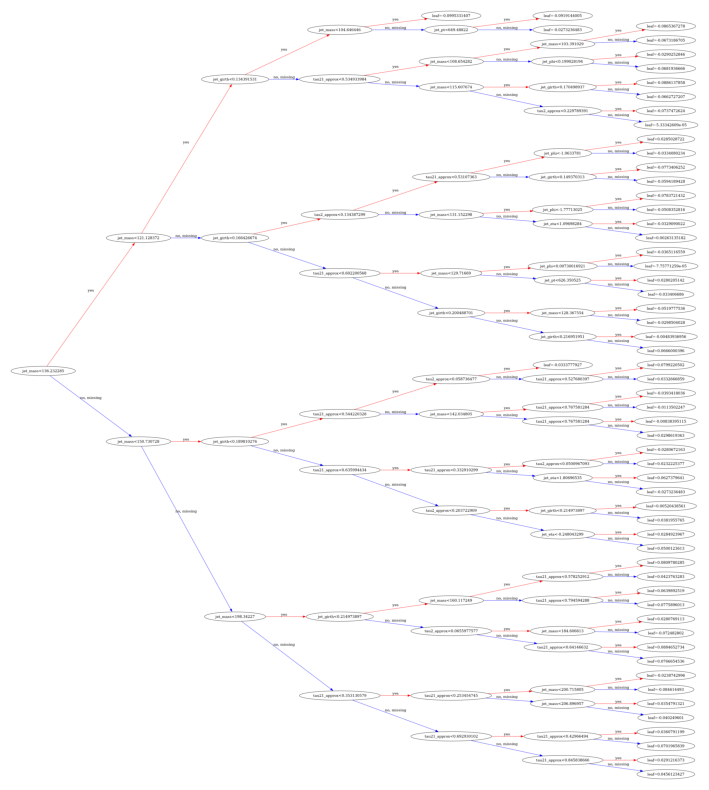

In [19]:
import matplotlib.pyplot as plt
import xgboost as xgb

xgb.plot_tree(clf_bdt, num_trees=0, rankdir="LR")
plt.gcf().set_size_inches(20, 10)
plt.show()

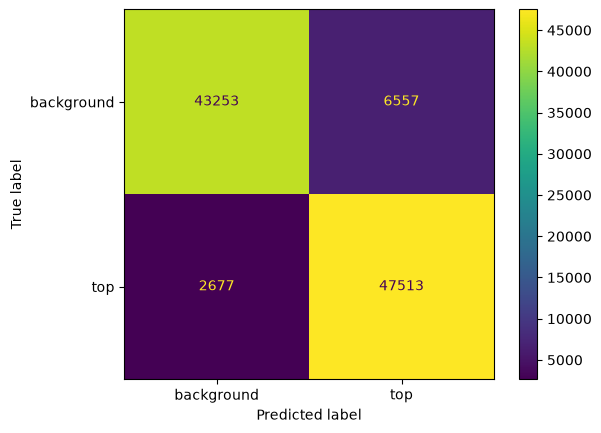

In [20]:
## plot_confusion_matrix() will run the test data down the tree and draw
## a confusion matrix.
ConfusionMatrixDisplay.from_estimator(clf_bdt, 
                                      X_val, 
                                      y_val, 
                                      display_labels=["background", "top"])

In [21]:
# Function for computing accuracy, precision, recall, and F1 score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred):
    """Helper function to compute accuracy, precision, recall, and F1 score at once."""
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Pretty print the metrics
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

In [22]:
# Testing model on training sets
y_train_pred = clf_bdt.predict(X_train)

# Compute metrics for training sets
print("Training Set Metrics:")
compute_metrics(y_train, y_train_pred)


Training Set Metrics:
Accuracy: 0.9252
Precision: 0.8952
Recall: 0.9633
F1 Score: 0.9280


In [23]:
# Testing model on test sets
y_val_pred = clf_bdt.predict(X_val)

# Compute metrics for test sets
print("validation Set Metrics:")
compute_metrics(y_val, y_val_pred)

validation Set Metrics:
Accuracy: 0.9077
Precision: 0.8787
Recall: 0.9467
F1 Score: 0.9114


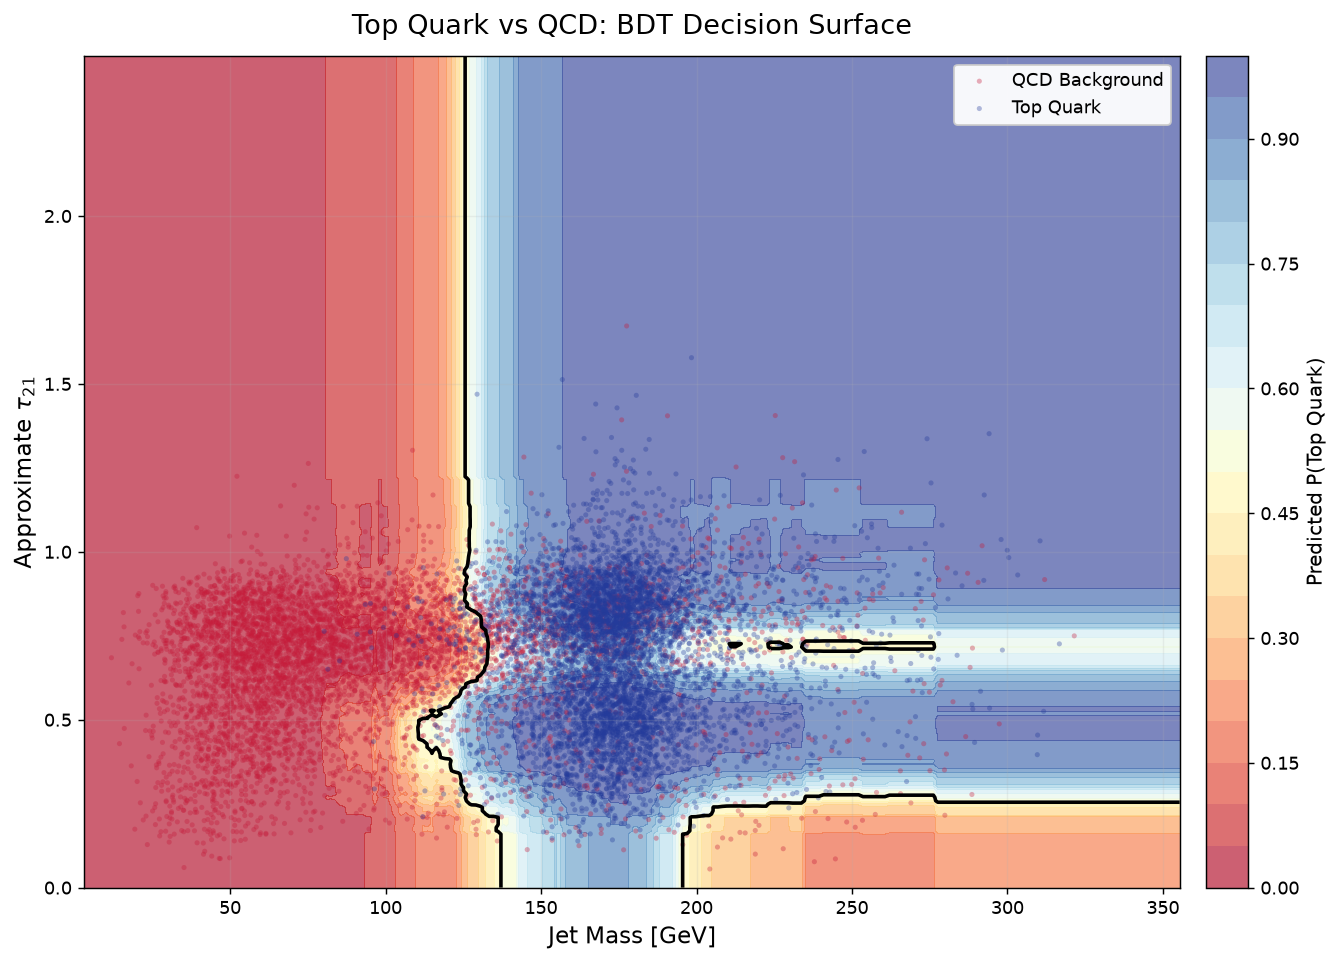

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# --------------------------------------------------
# 1. Select the two features for visualization
# --------------------------------------------------
feature_names = ["jet_mass", "tau21_approx"]
X_vis = X_train[feature_names].to_numpy()

# Assumption: positive labels correspond to Top Quark
y_vis = (np.asarray(y_train).ravel() > 0).astype(int)

# Use the already-trained BDT (10-feature model)
clf_vis = clf_bdt
feature_names_all = list(X_train.columns)

# --------------------------------------------------
# 2. Build a meshgrid
# --------------------------------------------------
x_min, x_max = X_vis[:, 0].min() - 5, X_vis[:, 0].max() + 5
y_min, y_max = max(0, X_vis[:, 1].min() - 0.05), min(
    2.5, X_vis[:, 1].max() + 0.05
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

# Keep all other features fixed at their training medians
reference = X_train.median()
X_grid = pd.DataFrame(
    np.tile(reference.to_numpy(), (xx.size, 1)),
    columns=feature_names_all
)

X_grid["jet_mass"] = xx.ravel()
X_grid["tau21_approx"] = yy.ravel()

# --------------------------------------------------
# 3. Predict Top Quark probability
# --------------------------------------------------
classes = list(clf_vis.classes_)

if 1 not in classes:
    raise ValueError(
        f"Expected Top Quark label 1, but model classes are {classes}"
    )

top_index = classes.index(1)

if hasattr(clf_vis, "predict_proba"):
    Z = clf_vis.predict_proba(X_grid)[:, top_index]
    Z = Z.reshape(xx.shape)
    colorbar_label = "Predicted P(Top Quark)"
else:
    raise AttributeError(
        "This model does not support predict_proba(). "
        "Check the classifier configuration."
    )

# --------------------------------------------------
# 4. Publication-style visualization
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7.5), dpi=130)

# Smooth probability shading
levels = np.linspace(0, 1, 21)
cf = ax.contourf(
    xx, yy, Z,
    levels=levels,
    cmap="RdYlBu",
    alpha=0.65,
    vmin=0,
    vmax=1
)

# The 50% probability boundary
if Z.min() <= 0.5 <= Z.max():
    ax.contour(
        xx, yy, Z,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

# Plot the actual classes separately to control colors
rng = np.random.default_rng(42)
n_plot = min(12000, len(X_vis))
idx = rng.choice(len(X_vis), size=n_plot, replace=False)

mask_qcd = (y_vis[idx] == 0)
mask_top = (y_vis[idx] == 1)

ax.scatter(
    X_vis[idx][mask_qcd, 0],
    X_vis[idx][mask_qcd, 1],
    s=8, c="#c51b3a", alpha=0.35,
    edgecolors="none", label="QCD Background",
    rasterized=True
)

ax.scatter(
    X_vis[idx][mask_top, 0],
    X_vis[idx][mask_top, 1],
    s=8, c="#243b9b", alpha=0.35,
    edgecolors="none", label="Top Quark",
    rasterized=True
)

# Labels and styling
ax.set_xlabel(r"Jet Mass [GeV]", fontsize=13)
ax.set_ylabel(r"Approximate $\tau_{21}$", fontsize=13)
ax.set_title(
    "Top Quark vs QCD: BDT Decision Surface",
    fontsize=15, pad=12
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(alpha=0.18)
ax.legend(loc="upper right", framealpha=0.95)

cbar = fig.colorbar(cf, ax=ax, pad=0.02)
cbar.set_label(colorbar_label, fontsize=11)

plt.tight_layout()
plt.show()


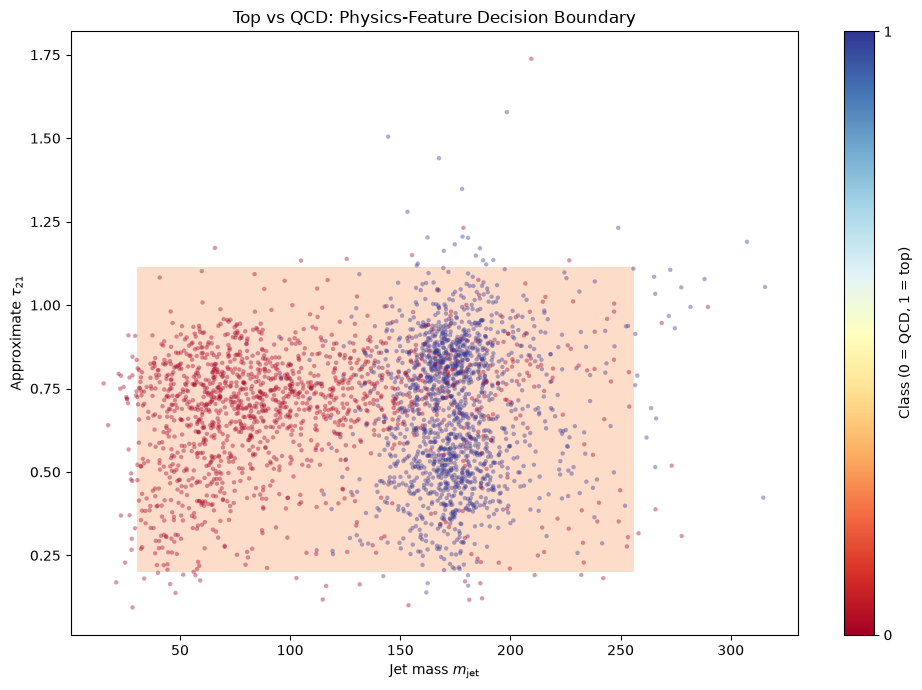

Predicted classes across grid: [0]


In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Your already-trained physics-feature model
model = clf_bdt

# Select two physics observables
feature_names = ["jet_mass", "tau21_approx"]
feature_idx = [X_train.columns.get_loc(f) for f in feature_names]

# Fix remaining physics features to a reference training jet
reference_jet = X_train.iloc[[0]].to_numpy()

# Grid limits: use central 1%-99% of each feature
x_min, x_max = X_train[feature_names[0]].quantile([0.01, 0.99])
y_min, y_max = X_train[feature_names[1]].quantile([0.01, 0.99])

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

# Create model inputs
grid = np.repeat(reference_jet, xx.size, axis=0)
grid[:, feature_idx[0]] = xx.ravel()
grid[:, feature_idx[1]] = yy.ravel()

# Predict using the trained model; no fit()
Z = model.predict(grid).reshape(xx.shape)

# Plot decision regions and boundary
fig, ax = plt.subplots(figsize=(10, 7))

ax.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.3,
    cmap=plt.cm.RdYlBu
)

# Draw the class-transition boundary
ax.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Plot a sample of actual training jets
sample = X_train.sample(min(3000, len(X_train)), random_state=42)
sample_labels = y_train.loc[sample.index].to_numpy()

ax.scatter(
    sample[feature_names[0]],
    sample[feature_names[1]],
    c=sample_labels,
    cmap=plt.cm.RdYlBu,
    s=10,
    alpha=0.4,
    edgecolors="none"
)

ax.set_xlabel(r"Jet mass $m_{\mathrm{jet}}$")
ax.set_ylabel(r"Approximate $\tau_{21}$")
ax.set_title("Top vs QCD: Physics-Feature Decision Boundary")

fig.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(0, 1),
        cmap=plt.cm.RdYlBu
    ),
    ax=ax,
    ticks=[0, 1],
    label="Class (0 = QCD, 1 = top)"
)

plt.tight_layout()
plt.show()

print("Predicted classes across grid:", np.unique(Z))

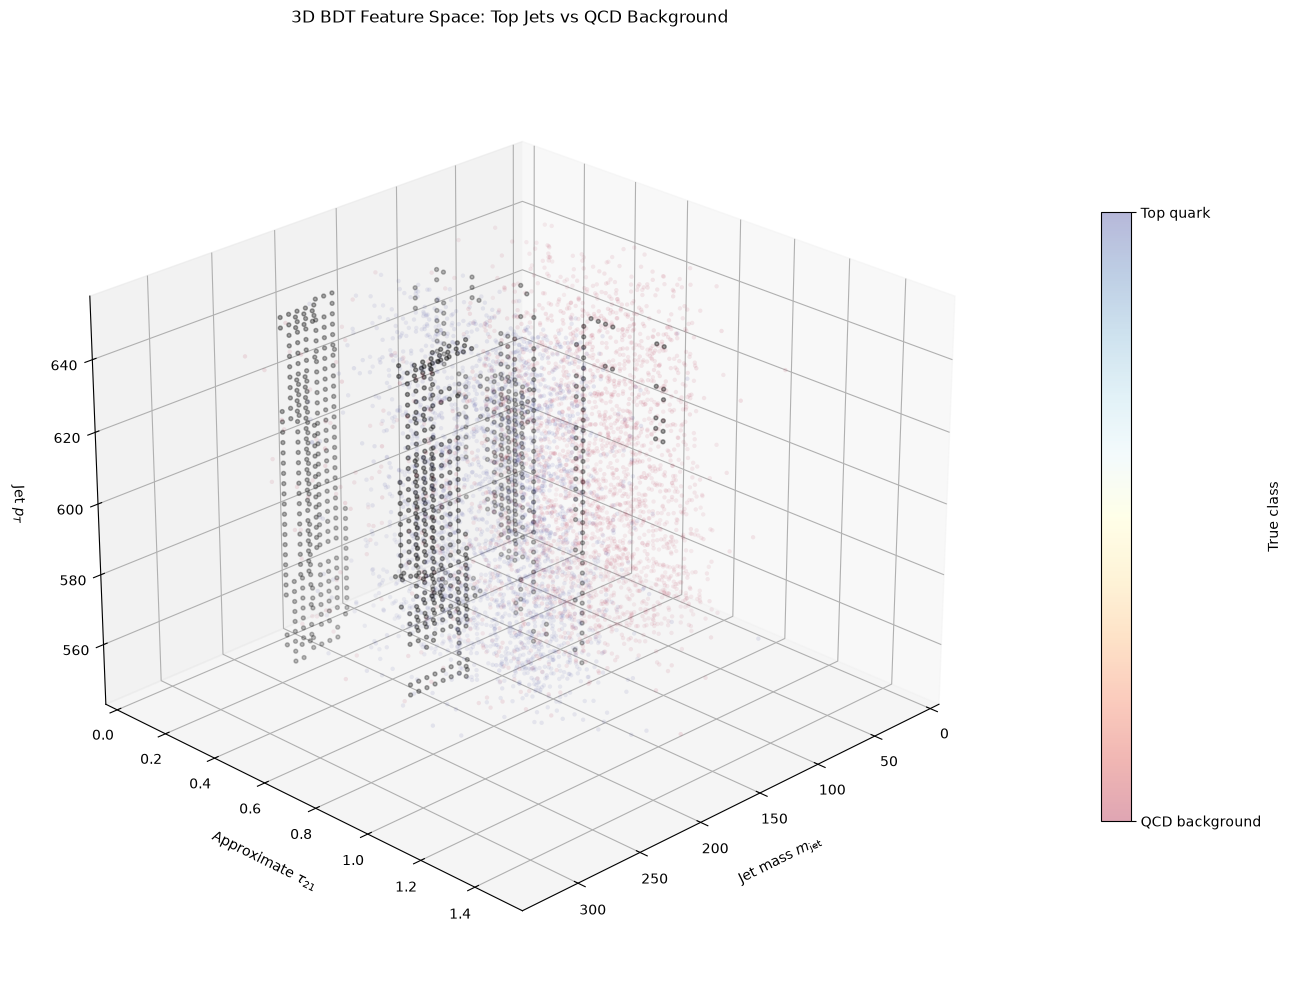

In [26]:

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

# --------------------------------------------------
# 1. Select three physics features
# --------------------------------------------------
feature_names = ["jet_mass", "tau21_approx", "jet_pt"]

X_vis = X_train[feature_names].to_numpy()
y = np.asarray(y_train).reshape(-1)
y = (y > 0).astype(int)

clf_vis = clf_bdt

# --------------------------------------------------
# 2. Build a 3D grid
#    Keep all 10 BDT features; vary only these 3
# --------------------------------------------------
all_features = list(X_train.columns)

mass_idx = all_features.index("jet_mass")
tau21_idx = all_features.index("tau21_approx")
pt_idx = all_features.index("jet_pt")

# Use central 98% of each feature's distribution
mass_min, mass_max = X_train["jet_mass"].quantile([0.01, 0.99])
tau_min, tau_max = X_train["tau21_approx"].quantile([0.01, 0.99])
pt_min, pt_max = X_train["jet_pt"].quantile([0.01, 0.99])

mass_grid = np.linspace(mass_min, mass_max, 35)
tau_grid = np.linspace(tau_min, tau_max, 35)
pt_grid = np.linspace(pt_min, pt_max, 35)

MM, TT, PP = np.meshgrid(
    mass_grid, tau_grid, pt_grid, indexing="ij"
)

# Hold the remaining 7 features at their training medians
reference = X_train.median().to_numpy()
X_grid = np.tile(reference, (MM.size, 1))

X_grid[:, mass_idx] = MM.ravel()
X_grid[:, tau21_idx] = TT.ravel()
X_grid[:, pt_idx] = PP.ravel()

# Probability that an event is a top jet
P_top = clf_vis.predict_proba(X_grid)[:, 1]
P_top = P_top.reshape(MM.shape)

# Identify grid points close to the decision threshold
boundary_mask = np.abs(P_top - 0.5) < 0.04

# --------------------------------------------------
# 3. Sample the real training events for visualization
# --------------------------------------------------
rng = np.random.default_rng(42)
n_plot = min(5000, len(X_train))
sample_idx = rng.choice(len(X_train), size=n_plot, replace=False)

X_sample = X_vis[sample_idx]
y_sample = y[sample_idx]

# --------------------------------------------------
# 4. Plot in 3D
# --------------------------------------------------
fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection="3d")

# True training labels: QCD = 0, top = 1
scatter = ax.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    X_sample[:, 2],
    c=y_sample,
    cmap=plt.cm.RdYlBu,
    norm=Normalize(vmin=0, vmax=1),
    s=10,
    alpha=0.35,
    edgecolors="none"
)

# Approximate decision-boundary points
if np.any(boundary_mask):
    ax.scatter(
        MM[boundary_mask],
        TT[boundary_mask],
        PP[boundary_mask],
        color="black",
        s=8,
        alpha=0.65,
        label=r"Near $P(\mathrm{top})=0.5$"
    )
else:
    print(
        "No grid points near P(top)=0.5. "
        "Try a wider threshold, e.g. 0.08, "
        "or increase grid resolution."
    )

# Axis labels
ax.set_xlabel(r"Jet mass $m_{\mathrm{jet}}$", labelpad=12)
ax.set_ylabel(r"Approximate $\tau_{21}$", labelpad=12)
ax.set_zlabel(r"Jet $p_T$", labelpad=12)

ax.set_title(
    "3D BDT Feature Space: Top Jets vs QCD Background",
    pad=20
)

# Colorbar for true class
cbar = fig.colorbar(scatter, ax=ax, pad=0.10, shrink=0.65)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["QCD background", "Top quark"])
cbar.set_label("True class")

ax.view_init(elev=25, azim=45)
ax.grid(True)

plt.tight_layout()
plt.show()


Validation ROC-AUC: 0.9652

Classification report:
                precision    recall  f1-score   support

QCD Background     0.9417    0.8684    0.9036     49810
     Top Quark     0.8787    0.9467    0.9114     50190

      accuracy                         0.9077    100000
     macro avg     0.9102    0.9075    0.9075    100000
  weighted avg     0.9101    0.9077    0.9075    100000



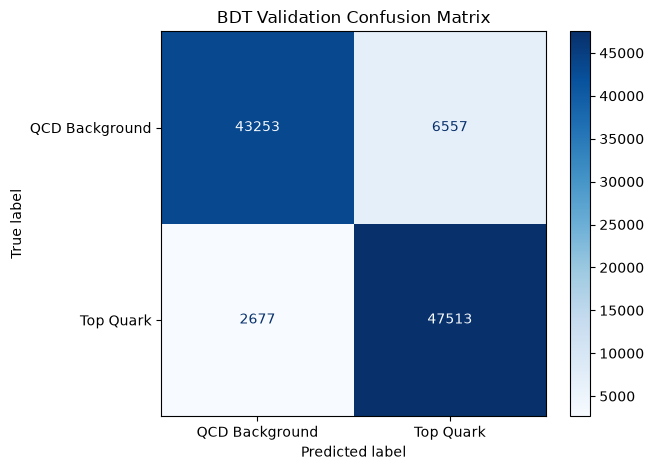

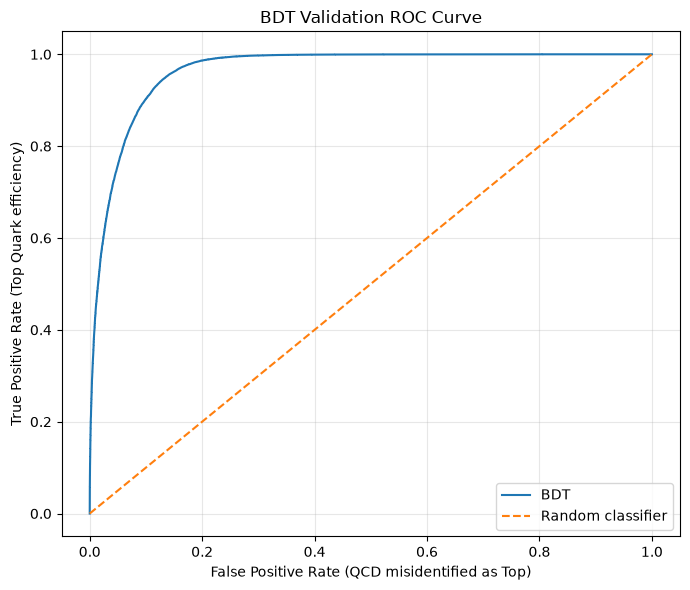

In [27]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    classification_report
)

# Ensure labels use 0 = QCD, 1 = Top Quark
y_true = (np.asarray(y_val).ravel() > 0).astype(int)

# Predict using your trained BDT
y_pred = clf_bdt.predict(X_val)

# Convert predictions to binary labels if necessary
y_pred = (np.asarray(y_pred).ravel() > 0).astype(int)

# Probability of the Top Quark class
classes = list(clf_bdt.classes_)
top_idx = classes.index(1)
y_score = clf_bdt.predict_proba(X_val)[:, top_idx]

# Quantitative evaluation
print("Validation ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["QCD Background", "Top Quark"],
    digits=4
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=["QCD Background", "Top Quark"],
    cmap="Blues",
    values_format="d"
)
plt.title("BDT Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_score)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label="BDT")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate (QCD misidentified as Top)")
plt.ylabel("True Positive Rate (Top Quark efficiency)")
plt.title("BDT Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


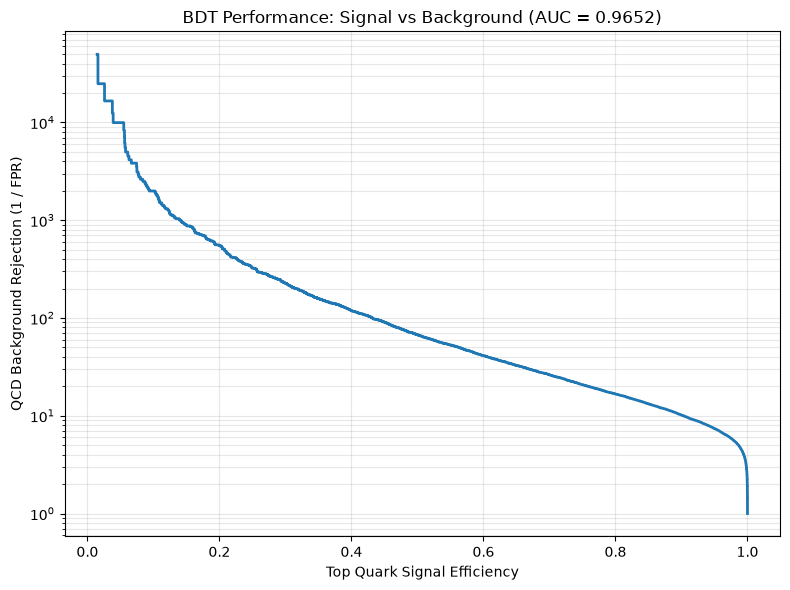

Signal efficiency: 0.500 | QCD rejection: 67.31 | FPR: 0.01486
Signal efficiency: 0.700 | QCD rejection: 26.28 | FPR: 0.03804
Signal efficiency: 0.800 | QCD rejection: 16.73 | FPR: 0.05977
Signal efficiency: 0.900 | QCD rejection: 10.18 | FPR: 0.09819
Signal efficiency: 0.950 | QCD rejection: 7.40 | FPR: 0.13505


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_true = (np.asarray(y_val).ravel() > 0).astype(int)

classes = list(clf_bdt.classes_)
top_idx = classes.index(1)
y_score = clf_bdt.predict_proba(X_val)[:, top_idx]

fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

# Avoid division by zero at FPR = 0
background_rejection = np.divide(
    1.0, fpr,
    out=np.full_like(fpr, np.nan),
    where=fpr > 0
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(tpr, background_rejection, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("Top Quark Signal Efficiency")
ax.set_ylabel("QCD Background Rejection (1 / FPR)")
ax.set_title(f"BDT Performance: Signal vs Background (AUC = {auc:.4f})")
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# Report background rejection at selected signal efficiencies
for target_eff in [0.50, 0.70, 0.80, 0.90, 0.95]:
    i = np.argmin(np.abs(tpr - target_eff))
    rejection = 1 / fpr[i] if fpr[i] > 0 else np.inf

    print(
        f"Signal efficiency: {tpr[i]:.3f} | "
        f"QCD rejection: {rejection:.2f} | "
        f"FPR: {fpr[i]:.5f}"
    )


In [29]:
import tables
import pandas as pd

N = 100_000

with tables.open_file("test.h5", mode="r") as h5:
    table = h5.root.table.table

    feature_names = list(table.attrs.values_block_0_kind)

    X_test = pd.DataFrame(
        table.read(
            field="values_block_0",
            start=0,
            stop=N
        )[:, :800],
        columns=feature_names[:800]
    )

    y_test = pd.Series(
        table.read(
            field="values_block_1",
            start=0,
            stop=N
        )[:, 1],
        name="is_signal_new"
    )

print("X_train:", X_test.shape)
print("y_train:", y_test.shape)
print(y_test.value_counts())
display(X_test.head(20))
display(y_test.head(50))

X_train: (100000, 800)
y_train: (100000,)
is_signal_new
0    50570
1    49430
Name: count, dtype: int64


,E_0,PX_0,PY_0,PZ_0,E_1,PX_1,PY_1,PZ_1,E_2,PX_2,...,PY_197,PZ_197,E_198,PX_198,PY_198,PZ_198,E_199,PX_199,PY_199,PZ_199
0,218.364243,-172.341858,110.129105,-76.503624,153.661118,-111.320465,93.167969,-50.390713,76.708054,-56.523701,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,122.238762,26.738468,-91.613998,76.382225,121.227135,17.644758,-93.015450,75.715302,90.420105,21.377417,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,383.772308,-97.906456,79.640709,-362.426361,200.625992,-54.921326,37.994343,-189.184753,123.247223,-33.828953,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,132.492752,-77.763947,-87.322601,-62.304600,83.946594,-49.450481,-53.823605,-41.288010,28.072624,-19.964916,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,730.786987,-209.120010,-193.454315,-672.973877,225.477325,-75.363350,-66.226990,-201.926651,217.040192,-63.698189,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,425.659546,323.020142,-155.901611,-229.213257,83.688065,63.508339,-30.651501,-45.065155,35.438320,25.900942,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,184.878754,-163.308701,-48.425228,71.870857,39.259518,-34.826504,-6.211102,17.024878,36.229164,-31.835764,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,337.542389,-144.905655,52.931824,-300.225647,194.716293,-83.677284,30.484045,-173.156784,115.748047,-52.055187,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,57.453899,8.245859,54.802525,15.153853,48.546764,-30.239859,37.749592,4.160240,49.887844,-4.153875,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,269.725555,197.983688,180.264572,-32.542664,170.214188,112.955109,125.723831,-20.187439,47.387337,35.194256,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    1
31    1
32    1
33    1
34    1
35    1
36    1
37    1
38    1
39    1
40    0
41    0
42    0
43    0
44    0
45    0
46    0
47    0
48    0
49    0
Name: is_signal_new, dtype: int64

In [30]:
X_test, y_test = calculate_physics_features(
    "test.h5",
    N=100_000
)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print(y_test.value_counts())

display(X_test.head())
display(y_test.head())

X_test shape: (100000, 10)
y_test shape: (100000,)
is_signal_new
0    50570
1    49430
Name: count, dtype: int64


,jet_mass,jet_pt,jet_eta,jet_phi,constituent_multiplicity,jet_girth,pt_dispersion,tau1_approx,tau2_approx,tau21_approx
0,73.591760,604.311757,-0.346399,2.479703,17,0.073847,0.454447,0.092309,0.033274,0.360468
1,113.147389,564.015542,0.701126,-1.316133,61,0.117589,0.286965,0.146986,0.112172,0.763146
2,71.595126,646.006196,-1.769740,2.528747,45,0.074345,0.275832,0.092932,0.070438,0.757958
3,150.704152,577.558525,-0.519466,-2.435416,74,0.209741,0.261896,0.262176,0.216944,0.827475
4,64.424290,630.410209,-1.562158,-2.403369,30,0.070668,0.503150,0.088335,0.034701,0.392838


0    0
1    0
2    0
3    0
4    0
Name: is_signal_new, dtype: int64

TEST SET METRICS
-----------------------------------
Accuracy : 0.9081
Precision: 0.8754
Recall   : 0.9491
F1 Score : 0.9108
ROC-AUC  : 0.9663

Classification Report
                precision    recall  f1-score   support

QCD Background     0.9458    0.8680    0.9052     50570
     Top Quark     0.8754    0.9491    0.9108     49430

      accuracy                         0.9081    100000
     macro avg     0.9106    0.9085    0.9080    100000
  weighted avg     0.9110    0.9081    0.9080    100000



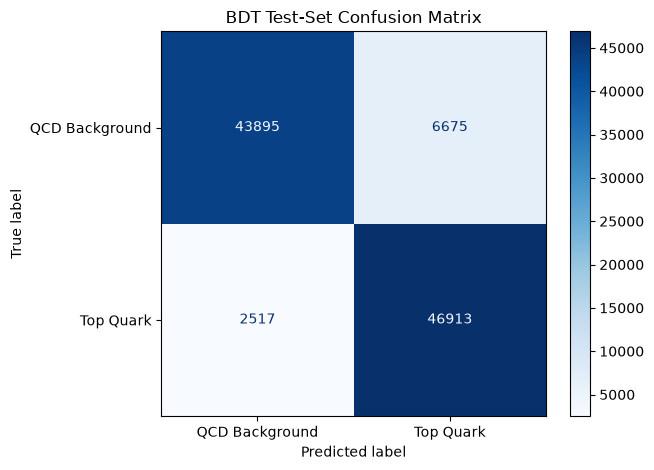

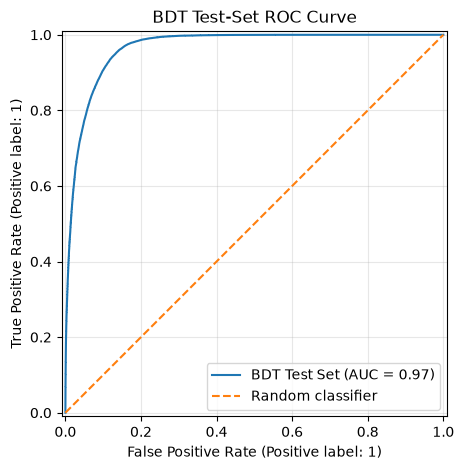

In [31]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Convert labels to 0 = QCD, 1 = Top Quark
y_true = (np.asarray(y_test).ravel() > 0).astype(int)

# Predict using the already-trained BDT
y_pred = (np.asarray(clf_bdt.predict(X_test)).ravel() > 0).astype(int)

# Get Top Quark probability
classes = list(clf_bdt.classes_)
top_idx = classes.index(1)
y_score = clf_bdt.predict_proba(X_test)[:, top_idx]

# Metrics
print("TEST SET METRICS")
print("-" * 35)
print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1 Score : {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_true, y_score):.4f}")

print("\nClassification Report")
print(classification_report(
    y_true, y_pred,
    target_names=["QCD Background", "Top Quark"],
    digits=4,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=["QCD Background", "Top Quark"],
    cmap="Blues",
    values_format="d"
)
plt.title("BDT Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(
    y_true, y_score, name="BDT Test Set"
)
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.title("BDT Test-Set ROC Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [32]:
import joblib

# Assuming clf_bdt is your trained model object
# Save the model to a file
joblib.dump(clf_bdt, 'clf_bdt_model.pkl')


['clf_bdt_model.pkl']